# Pembersihan Data Kualitas Udara Indonesia (AQMS + Kesehatan)
Notebook ini mengubah 33 file mentah menjadi dataset bersih siap analisis dan dasbor.

**Cara pakai di Google Colab**
1. Jalankan sel demi sel dari atas (Runtime → Run all juga bisa).
2. Saat sel *Sumber data* berjalan, Colab meminta izin mengakses Google Drive. Klik **Izinkan** dan pilih akun yang sama dengan tempat file Anda disimpan.
3. Notebook mencari `Dataset_DA_Gelar_Rasa_2026.zip` di My Drive (termasuk subfolder). Jika Anda mengunggah file yang sudah diekstrak, notebook mencari folder yang berisi `sites.csv`.
4. Hasil disimpan otomatis ke folder `hasil_bersih` di My Drive.

**Keluaran**
| File | Isi |
|---|---|
| `aqms_hourly_clean.csv` | Data per jam, semua stasiun layak, satuan seragam µg/m³ |
| `aqms_daily_clean.csv` | Rata-rata 24 jam per stasiun (syarat ≥ 18 jam data) |
| `health_clean.csv` | Data kesehatan harian + kode lokasi stasiun |
| `analysis_daily_merged.csv` | Udara harian + kesehatan, siap uji lag |
| `stations_master_clean.csv` | Tabel stasiun + pulau + status kualitas |
| `station_quality_report.csv` | **Log audit**: apa saja yang dibuang/diubah per stasiun, termasuk hari valid PM2.5/SO2/NO2 |
| `iku_station_year.csv` | Estimasi IKU per stasiun per tahun (SO2 + NO2), lengkap dengan hari valid dan status kelayakan |
| `iku_city_year.csv` | Estimasi IKU per kabupaten/kota per tahun (dari stasiun yang layak) |
| `data_dictionary.csv` | Kamus kolom hasil |

## 1. Konfigurasi dan asumsi

| Parameter | Nilai bawaan | Alasan |
|---|---|---|
| `ACCEPT_FLAGS` | hanya `VALID` | Pada Merauke, baris `SUSPECT` berisi PM2.5 hingga 1.449 padahal PM10 hanya ±29 (mustahil secara fisik); pada Samarinda `SUSPECT` = kode 999 dan `CALIBRATING` = 0. Memakai `VALID` saja adalah pilihan paling aman. **Pengecualian:** stasiun di `SUSPECT_ACCEPT_STATIONS` (Samarinda), lihat baris di bawah. |
| `PM_PPM_FACTOR` | 1000 | **Asumsi, bukan standar fisika.** PM tidak punya berat molekul sehingga ppm → µg/m³ tidak bisa dihitung. Faktor ini dipilih karena menghasilkan nilai yang cocok dengan `baseline_pm25`. Lihat sel uji sensitivitas. |
| `MOLAR_VOLUME` | 24,45 L/mol | Konversi gas pada 25 °C, 1 atm. |
| `MIN_HOURS_PER_DAY` | 18 | Syarat kelengkapan 75% untuk rata-rata 24 jam. |
| `COVERAGE_EXCLUDE` | 10% | Stasiun dengan cakupan PM2.5 di bawah ini dikeluarkan dari analisis. |
| `COVERAGE_OK` | 80% | Di bawah ini tetapi di atas batas keluar = status `CAUTION`. |
| `IKU_REF_SO2` / `IKU_REF_NO2` | 20 / 40 µg/m³ | Acuan model EU pada panduan KLHK (Program Langit Biru) untuk Permen LHK 27/2021. **Cek ulang di lampiran Permen.** |
| `IKU_MIN_FRACTION` | 80% | Syarat kelengkapan AQMS stasiun tetap: ≥ 80% hari valid per tahun (292 dari 365 hari). |
| `IKU_CLIP` | True | Nilai IKU dipotong ke 0–100. Asumsi: belum diverifikasi dari teks Permen. Nilai mentah tetap disimpan di `iku_raw`. |
| `FROZEN_MIN_RUN` / `FROZEN_MIN_VARS` | 24 jam / 3 polutan | Nilai identik persis ≥ 24 jam berturut-turut di ≥ 3 polutan sekaligus = sensor/logger macet. Pada Banjarbaru ada 7.329 jam (30%) seperti ini yang berflag `VALID`. Run identik terpanjang di stasiun lain hanya 5 jam. Berbeda dari `MIN_HOURS_PER_DAY` (kelengkapan data). |
| `SUSPECT_ACCEPT_STATIONS` | `LOC-SM2-01` | Di Samarinda semua baris `SUSPECT` jatuh di Jul-Okt (musim asap). Yang bukan kode 999 bernilai konsisten (rasio PM2.5/PM10 0,58 vs 0,59 pada `VALID`) dan diterima bila lolos cek fisika. Memakai `VALID` saja menurunkan rata-rata tahunan 20-25%. |
| `OVERRANGE_CODE` | 999 | Baris `SUSPECT` ber-PM 999 (PM2.5 dan PM10 sekaligus) dikosongkan, tetapi **ditandai** `pm25_overrange`: kemungkinan jam asap terparah, jadi PM2.5 Samarinda dibaca sebagai **batas bawah**. |


In [ ]:
import re, zipfile, math, warnings, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)

# ======================= KONFIGURASI =======================
ACCEPT_FLAGS     = {"VALID"}      # flag qc yang dipakai. Tambah "SUSPECT" dst. jika ingin lebih longgar
PM_PPM_FACTOR    = 1000.0         # ASUMSI: PM dalam ppm -> ug/m3 (lihat catatan di atas)
MOLAR_VOLUME     = 24.45          # L/mol pada 25 C, 1 atm
MIN_HOURS_PER_DAY = 18            # 75% dari 24 jam
COVERAGE_OK      = 0.80
COVERAGE_EXCLUDE = 0.10
PM_RATIO_TOL     = 1.10           # PM2.5 boleh melebihi PM10 maksimal 10% (+1 ug/m3) karena toleransi alat
MIN_ROW_FRACTION = 0.5            # untuk data sub-jam: minimal 50% pembacaan dalam sejam harus lolos
OUT = Path("hasil_bersih")        # folder keluaran sementara (lokal)

# --- IKU (Permen LHK 27/2021): hanya SO2 dan NO2, rata-rata tahunan
IKU_REF_SO2      = 20.0           # ug/m3, acuan EU (panduan KLHK) -> cek ulang di lampiran Permen
IKU_REF_NO2      = 40.0           # ug/m3
IKU_MIN_FRACTION = 0.80           # >= 80% hari valid per tahun (292 dari 365)
IKU_CLIP         = True           # potong IKU ke 0-100 (asumsi); iku_raw tetap disimpan

# --- Nilai beku (sensor macet): nilai identik persis berturut-turut
FROZEN_MIN_RUN   = 24             # minimal jam berturut-turut dengan nilai identik
FROZEN_MIN_VARS  = 3              # ...dan terjadi bersamaan di minimal sekian polutan -> jam dikosongkan

# --- Perlakuan khusus SUSPECT (hanya stasiun yang sudah dibuktikan lewat diagnostik)
SUSPECT_ACCEPT_STATIONS = {"LOC-SM2-01"}   # Samarinda: SUSPECT hanya muncul Jul-Okt (musim asap)
OVERRANGE_CODE   = 999            # kode PM "melewati rentang": jam dikosongkan + ditandai pm25_overrange

# --- Google Drive
DRIVE_ROOT       = Path("/content/drive/MyDrive")
ZIP_PATTERN      = "Dataset_DA_Gelar_Rasa_2026*.zip"   # nama zip yang dicari
DRIVE_ZIP_PATH   = None   # isi bila tahu lokasi pastinya, mis. "/content/drive/MyDrive/Lomba/Dataset_DA_Gelar_Rasa_2026.zip"
SAVE_TO_DRIVE    = True   # salin hasil ke My Drive/hasil_bersih
DRIVE_OUT        = DRIVE_ROOT / "hasil_bersih"
DOWNLOAD_ZIP     = False  # True = unduh juga hasil_bersih.zip ke komputer
# ============================================================

try:
    from google.colab import files, drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Colab:", IN_COLAB, "| pandas", pd.__version__)

Colab: True | pandas 2.2.3


## 2. Sumber data: Google Drive

In [ ]:
if IN_COLAB and not DRIVE_ROOT.exists():
    drive.mount("/content/drive")        # akan muncul jendela izin akses

source = None   # (jenis, path)
if DRIVE_ROOT.exists():
    if DRIVE_ZIP_PATH:
        cand = [Path(DRIVE_ZIP_PATH)]
    else:
        cand = sorted(DRIVE_ROOT.glob(ZIP_PATTERN)) or sorted(DRIVE_ROOT.rglob(ZIP_PATTERN))
    cand = [p for p in cand if p.exists()]
    if cand:
        source = ("zip", cand[0])
    else:
        hits = sorted(DRIVE_ROOT.rglob("sites.csv"))
        if hits:
            source = ("folder", hits[0].parent)
if source is None:                          # cadangan: zip di folder kerja atau unggah manual
    local = sorted(Path(".").glob("*.zip"))
    if not local and IN_COLAB:
        print("Tidak ditemukan di Drive. Pilih file zip dari komputer ...")
        files.upload(); local = sorted(Path(".").glob("*.zip"))
    assert local, "Data tidak ditemukan. Pastikan zip/folder ada di My Drive, atau isi DRIVE_ZIP_PATH di sel konfigurasi."
    source = ("zip", local[0])

kind, src_path = source
if kind == "zip":
    RAW = Path("data_raw")                  # folder lokal sementara (aman dihapus)
    if RAW.exists():
        shutil.rmtree(RAW)
    RAW.mkdir()
    with zipfile.ZipFile(src_path) as z:
        z.extractall(RAW)
else:
    RAW = src_path                          # baca langsung dari Drive, TIDAK dihapus/diubah
print(f"Sumber: {kind} -> {src_path}")

def find(name):
    hits = sorted(RAW.rglob(name))
    assert hits, f"{name} tidak ditemukan di {RAW}"
    return hits[0]

n_aqms = len(list(RAW.rglob("*_AQMS.csv")))
print(f"File AQMS: {n_aqms} (harapan 27) | HLT-01: {len(list(RAW.rglob('HLT-01*.csv')))} | sites.csv: {len(list(RAW.rglob('sites.csv')))}")
assert n_aqms == 27, "Jumlah file AQMS tidak 27. Periksa apakah semua file terunggah ke Drive."

Mounted at /content/drive
Tidak ditemukan di Drive. Pilih file zip dari komputer ...


Saving Dataset DA Gelar Rasa 2026.zip to Dataset DA Gelar Rasa 2026.zip
Sumber: zip -> Dataset DA Gelar Rasa 2026.zip
File AQMS: 27 (harapan 27) | HLT-01: 1 | sites.csv: 1


## 3. Tabel master dan katalog stasiun
Stasiun dihubungkan lewat `sensor_id` yang ada **di dalam** file


In [ ]:
sites       = pd.read_csv(find("sites.csv"))
sensors     = pd.read_csv(find("sensors.csv"))
hospitals   = pd.read_csv(find("hospitals.csv"))
meta_dates  = pd.read_csv(find("metadata_dates.csv"))
meta_sensor = pd.read_csv(find("metadata_sensors.csv"))
HEALTH_PATH = find("HLT-01_health_outcomes_daily.csv")

# periode pengamatan resmi dari metadata
PERIOD_START = pd.to_datetime(meta_dates["date_start"]).min().floor("h")
PERIOD_END   = pd.to_datetime(meta_dates["date_end"]).max().floor("h")
FULL_HOURS   = pd.date_range(PERIOD_START, PERIOD_END, freq="h")
print("Periode:", PERIOD_START, "->", PERIOD_END, "|", len(FULL_HOURS), "jam")

# katalog file AQMS
rows = []
for p in sorted(RAW.rglob("*_AQMS.csv")):
    sid = pd.read_csv(p, nrows=1, dtype=str)["sensor_id"].iloc[0]
    rows.append({"path": p, "label": p.stem.replace("_AQMS", ""), "sensor_id": sid})
catalog = pd.DataFrame(rows).merge(sensors[["sensor_id", "location_id"]], on="sensor_id", how="left")
assert len(catalog) == 27, f"Jumlah file AQMS = {len(catalog)}, harapan 27"
assert catalog.location_id.notna().all() and catalog.location_id.is_unique, "pemetaan sensor -> lokasi bermasalah"

ISLAND = {
    "Aceh": "Sumatera", "Sumatera Utara": "Sumatera", "Sumatera Barat": "Sumatera", "Riau": "Sumatera",
    "Jambi": "Sumatera", "Kepulauan Riau": "Sumatera", "Bengkulu": "Sumatera",
    "Sumatera Selatan": "Sumatera", "Lampung": "Sumatera",
    "DKI Jakarta": "Jawa", "Jawa Barat": "Jawa", "D.I. Yogyakarta": "Jawa", "DI Yogyakarta": "Jawa", "Jawa Timur": "Jawa",
    "Kalimantan Tengah": "Kalimantan", "Kalimantan Barat": "Kalimantan",
    "Kalimantan Timur": "Kalimantan", "Kalimantan Selatan": "Kalimantan",
    "Sulawesi Selatan": "Sulawesi", "Sulawesi Tengah": "Sulawesi",
    "Papua Barat Daya": "Papua", "Papua Selatan": "Papua",
}
stations = catalog.drop(columns="path").merge(sites, on="location_id", how="left")
stations["island"] = stations["provinsi"].map(ISLAND)
assert stations["island"].notna().all(), stations.loc[stations.island.isna(), "provinsi"].unique()
stations["pm_unit_source"] = np.where(stations["pm25_unit"].eq("ppm"), "ppm (dikonversi, asumsi)", "ug/m3")
print(stations.groupby("island").size().to_dict())
stations[["label", "location_id", "provinsi", "island", "site_type", "pm25_unit", "baseline_pm25"]]

Periode: 2024-01-01 00:00:00 -> 2026-10-14 23:00:00 | 24432 jam
{'Jawa': 7, 'Kalimantan': 6, 'Papua': 2, 'Sulawesi': 2, 'Sumatera': 10}


,label,location_id,provinsi,island,site_type,pm25_unit,baseline_pm25
0,BGL-01_Bengkulu,LOC-BGL-01,Bengkulu,Sumatera,Urban Coastal Background,ug/m3,25.0
1,BGR-01_Cisarua,LOC-BGR-01,Jawa Barat,Jawa,Regional / Clean Background,ug/m3,13.5
2,BGR-02_Baranangsiang,LOC-BGR-02,Jawa Barat,Jawa,Traffic / Roadside,ug/m3,26.0
3,BJB-01_Banjarbaru,LOC-BJB-01,Kalimantan Selatan,Kalimantan,Airport & Peatland Buffer,ppm,35.0
4,BTM-01_Batam,LOC-BTM-01,Kepulauan Riau,Sumatera,Industrial Perimeter / Maritime,ug/m3,38.0
5,IDP-01_Indrapuri,LOC-IDP-01,Aceh,Sumatera,Regional / Clean Background,ug/m3,9.7
6,JKT-01_Gambir,LOC-JKT-01,DKI Jakarta,Jawa,Urban Background,ug/m3,37.5
7,JKT-02_Marunda,LOC-JKT-02,DKI Jakarta,Jawa,Industrial Perimeter,ug/m3,55.0
8,JKT-03_Cengkareng,LOC-JKT-03,DKI Jakarta,Jawa,Traffic / Roadside,ug/m3,39.0
9,JMB-01_KotaJambi,LOC-JMB-01,Jambi,Sumatera,Peatland Buffer / Urban,ug/m3,32.0


## 4. Fungsi pembersih stasiun
Urutan langkah untuk setiap file:
1. Baca semua kolom sebagai teks, lalu ubah ke angka. Teks rusak (`ERR`, `0xDEADBEEF`, `#VALUE!`, `INF`) menjadi kosong.
2. Nilai sentinel yang pasti mustahil (`-9999`, `-999`, `-99`, `9999`, `99999`) menjadi kosong. Kode `999` **tidak** dihapus di tahap ini karena bisa nilai asli (mis. CO 999 µg/m³ di Palangka Raya); kasus 999 yang sebenarnya (Samarinda) sudah tertangkap oleh `qc_flag`.
3. **Seragamkan satuan ke µg/m³** (gas: rumus molar; PM: faktor asumsi).
4. Buang baris dengan timestamp rusak atau di luar periode (mis. `1970-01-01`).
5. Buang baris yang `qc_flag`-nya tidak diterima (kecuali `SUSPECT` non-999 di `SUSPECT_ACCEPT_STATIONS`; baris 999 dikosongkan dan ditandai).
6. Batas fisik per variabel; PM2.5 tidak boleh lebih besar dari PM10.
7. Bulatkan waktu ke jam terdekat (offset menit tiap stasiun berbeda), rata-ratakan bila ada beberapa pembacaan per jam (Palembang berubah ke 15 menit mulai Sep 2024). Arah angin dirata-ratakan secara sirkular.
8. Susun ulang ke deret jam penuh sehingga celah data terlihat eksplisit.
9. **Kosongkan nilai beku**: jam di mana ≥ `FROZEN_MIN_VARS` polutan identik persis selama ≥ `FROZEN_MIN_RUN` jam berturut-turut (sensor macet). Dijalankan terakhir agar jam yang sudah kosong tidak ikut dihitung.

In [ ]:
POLL = ["pm25", "pm10", "so2", "co", "o3", "no2"]
WX   = ["temperature_c", "humidity_pct", "wind_speed_ms", "wind_direction_deg"]
VARS = POLL + WX
MW   = {"so2": 64.066, "co": 28.010, "o3": 47.998, "no2": 46.006}   # g/mol
SENTINELS = [-9999, -999.9, -999, -99.9, -99, 9999, 99999]   # 999/999.9 SENGAJA tidak dimasukkan: bisa nilai asli (mis. CO)
LIMITS = {  # batas fisik (satuan ug/m3, derajat C, %, m/s, derajat)
    "pm25": (0.1, 2000), "pm10": (0.1, 3000), "so2": (0, 3000), "co": (0, 60000),
    "o3": (0, 1000), "no2": (0, 1500),
    "temperature_c": (10, 45), "humidity_pct": (0, 100),
    "wind_speed_ms": (0, 50), "wind_direction_deg": (0, 360),
}

def to_number(s):
    """teks -> angka; kembalikan (nilai, jumlah teks tak terbaca termasuk INF)."""
    v = pd.to_numeric(s, errors="coerce")
    bad = int(((v.isna() & s.notna()) | np.isinf(v)).sum())
    return v.replace([np.inf, -np.inf], np.nan), bad

def frozen_hours_mask(df):
    """True pada jam di mana >= FROZEN_MIN_VARS polutan beku (nilai identik >= FROZEN_MIN_RUN pengamatan berturut-turut).
    df: indeks waktu jam, kolom POLL. Run dihitung pada deret nilai yang tidak kosong."""
    fz = pd.DataFrame(False, index=df.index, columns=POLL)
    for v in POLL:
        s = df[v].round(3).dropna()
        if s.empty:
            continue
        grp = (s != s.shift()).cumsum()
        longrun = s.groupby(grp).transform("size") >= FROZEN_MIN_RUN
        fz.loc[s.index[longrun.values], v] = True
    return fz.sum(axis=1) >= FROZEN_MIN_VARS

def clean_station(path, location_id):
    a = {"location_id": location_id, "frozen_hours": 0, "suspect_accepted": 0, "overrange_hours": 0}
    raw = pd.read_csv(path, dtype=str)
    a["rows_raw"] = len(raw)

    # --- 1-3: angka, sentinel, satuan
    unit, data = {}, {}
    a["unparseable"] = a["sentinel"] = 0
    for p in POLL:
        if f"{p}_ug_m3" in raw:   unit[p] = "ug/m3"; col = f"{p}_ug_m3"
        elif f"{p}_ppm" in raw:   unit[p] = "ppm";   col = f"{p}_ppm"
        else:
            unit[p] = None; data[p] = pd.Series(np.nan, index=raw.index); continue
        v, bad = to_number(raw[col]); a["unparseable"] += bad
        m = v.isin(SENTINELS); a["sentinel"] += int(m.sum()); v = v.mask(m)
        if unit[p] == "ppm":
            v = v * (MW[p] * 1000 / MOLAR_VOLUME) if p in MW else v * PM_PPM_FACTOR
        data[p] = v
    for w in WX:
        v, bad = to_number(raw[w]); a["unparseable"] += bad
        m = v.isin(SENTINELS); a["sentinel"] += int(m.sum())
        data[w] = v.mask(m)
    d = pd.DataFrame(data)
    a["pm_from_ppm"]  = unit["pm25"] == "ppm"
    a["gas_from_ppm"] = unit["co"] == "ppm"

    # --- 4: timestamp
    ts = pd.to_datetime(raw["timestamp_start"], errors="coerce")
    a["ts_unparseable"] = int(ts.isna().sum())
    out = (ts < PERIOD_START - pd.Timedelta("1D")) | (ts > PERIOD_END + pd.Timedelta("1D"))
    a["ts_out_of_period"] = int(out.sum())
    ts = ts.mask(out)
    hour_all = ts.dt.round("h")
    n_all = hour_all.value_counts()                     # jumlah pembacaan mentah per jam
    a["hours_multi_reading"] = int((n_all > 1).sum())
    a["max_readings_per_hour"] = int(n_all.max()) if len(n_all) else 0

    # --- 5: qc_flag (+ pengecualian SUSPECT untuk stasiun terpilih)
    flag = raw["qc_flag"].fillna("NA").str.strip().str.upper()
    susp_ok = pd.Series(False, index=raw.index)
    over_hours = pd.DatetimeIndex([])
    if location_id in SUSPECT_ACCEPT_STATIONS:
        sus = flag.eq("SUSPECT")
        over = sus & ((d["pm25"] == OVERRANGE_CODE) | (d["pm10"] == OVERRANGE_CODE))
        susp_ok = sus & ~over & ts.notna()
        over_hours = pd.DatetimeIndex(hour_all[over].dropna().unique())
        a["suspect_accepted"] = int(susp_ok.sum())
        a["overrange_hours"] = len(over_hours)
    accepted = flag.isin(ACCEPT_FLAGS) | susp_ok
    rej = flag[~accepted].value_counts()
    a["qc_rejected_total"] = int(rej.sum())
    a["qc_rejected_detail"] = "; ".join(f"{k}:{v}" for k, v in rej.items())
    keep = accepted & ts.notna()
    a["rows_accepted"] = int(keep.sum())
    d, ts_k = d[keep].copy(), ts[keep]

    # --- 6: batas fisik
    a["out_of_range"] = 0
    for k, (lo, hi) in LIMITS.items():
        m = (d[k] < lo) | (d[k] > hi)
        a["out_of_range"] += int(m.sum()); d[k] = d[k].mask(m)
    bad_pm = d["pm25"] > d["pm10"] * PM_RATIO_TOL + 1.0
    a["pm25_gt_pm10"] = int(bad_pm.sum())
    d.loc[bad_pm, ["pm25", "pm10"]] = np.nan

    # --- 7: agregasi per jam
    d["hour"] = ts_k.dt.round("h")
    rad = np.deg2rad(d["wind_direction_deg"])
    d["_s"], d["_c"] = np.sin(rad), np.cos(rad)
    g = d.groupby("hour")
    num = [v for v in VARS if v != "wind_direction_deg"]
    mean, cnt = g[num].mean(), g[num].count()
    wd = (np.degrees(np.arctan2(g["_s"].mean(), g["_c"].mean())) + 360) % 360
    mean["wind_direction_deg"] = wd
    cnt["wind_direction_deg"] = g["wind_direction_deg"].count()
    need = np.ceil(MIN_ROW_FRACTION * n_all).reindex(mean.index)
    mean = mean.where(cnt.ge(need, axis=0))
    mean["n_rows"] = g.size()

    # --- 8: deret jam penuh
    mean = mean.reindex(FULL_HOURS)
    mean["n_rows"] = mean["n_rows"].fillna(0).astype(int)
    mean.index.name = "hour"
    mean.insert(0, "location_id", location_id)
    mean["pm_from_ppm"] = a["pm_from_ppm"]

    # --- 9: nilai beku (sensor macet) -> kosongkan; dijalankan terakhir sebelum statistik cakupan
    frozen = frozen_hours_mask(mean)
    a["frozen_hours"] = int(frozen.sum())
    mean.loc[frozen, POLL] = np.nan
    mean["frozen"] = frozen
    mean["pm25_overrange"] = mean.index.isin(over_hours)

    a["hours_total"] = len(FULL_HOURS)
    a["hours_pm25"]  = int(mean["pm25"].notna().sum())
    a["coverage_pm25"] = a["hours_pm25"] / a["hours_total"]
    a["coverage_pm10"] = float(mean["pm10"].notna().mean())
    a["coverage_wx"]   = float(mean["temperature_c"].notna().mean())
    return mean.reset_index(), a

## 5. Jalankan untuk 27 stasiun

In [ ]:
frames, audits = [], []
for _, r in catalog.iterrows():
    df, a = clean_station(r["path"], r["location_id"])
    a["label"] = r["label"]
    frames.append(df); audits.append(a)
    print(f"{r['label']:<26} baris {a['rows_raw']:>6} -> diterima {a['rows_accepted']:>6} | cakupan PM2.5 {a['coverage_pm25']:6.1%}")

hourly_all = pd.concat(frames, ignore_index=True)
print("\nTotal baris jam (sebelum menyaring stasiun):", len(hourly_all))

BGL-01_Bengkulu            baris  24432 -> diterima  24307 | cakupan PM2.5  99.5%
BGR-01_Cisarua             baris  24432 -> diterima  23688 | cakupan PM2.5  97.0%
BGR-02_Baranangsiang       baris  24432 -> diterima  23695 | cakupan PM2.5  97.0%
BJB-01_Banjarbaru          baris  24432 -> diterima  24432 | cakupan PM2.5  70.0%
BTM-01_Batam               baris  24432 -> diterima  24278 | cakupan PM2.5  99.4%
IDP-01_Indrapuri           baris  24432 -> diterima  24322 | cakupan PM2.5  99.5%
JKT-01_Gambir              baris  24432 -> diterima  23454 | cakupan PM2.5  96.0%
JKT-02_Marunda             baris  24432 -> diterima  23480 | cakupan PM2.5  96.1%
JKT-03_Cengkareng          baris  24432 -> diterima  23470 | cakupan PM2.5  96.1%
JMB-01_KotaJambi           baris  24432 -> diterima  24264 | cakupan PM2.5  99.3%
JMB-02_MuaroJambi          baris  24432 -> diterima    121 | cakupan PM2.5   0.5%
KTB-01_Kototabang          baris  24432 -> diterima  24305 | cakupan PM2.5  99.5%
KTG-01_PalangkaR

## 6. Laporan kualitas dan status stasiun


In [ ]:
audit = pd.DataFrame(audits).merge(
    stations[["location_id", "provinsi", "island", "site_type", "baseline_pm25", "pm_unit_source"]],
    on="location_id")
med = hourly_all.groupby("location_id")["pm25"].median()
p95 = hourly_all.groupby("location_id")["pm25"].quantile(0.95)
audit["pm25_median"] = audit.location_id.map(med).round(1)
audit["pm25_p95"]    = audit.location_id.map(p95).round(1)
audit["median_vs_baseline"] = (audit.pm25_median / audit.baseline_pm25).round(2)

def status(c):
    return "EXCLUDED" if c < COVERAGE_EXCLUDE else ("CAUTION" if c < COVERAGE_OK else "OK")
audit["status"] = audit.coverage_pm25.map(status)

def note(r):
    n = []
    if r.status == "EXCLUDED": n.append("cakupan PM2.5 terlalu rendah, dikeluarkan dari analisis")
    if r.status == "CAUTION":  n.append("cakupan sebagian, tafsirkan dengan hati-hati")
    if r.pm_from_ppm:          n.append(f"semua polutan dilaporkan ppm; PM dikonversi dengan faktor asumsi x{PM_PPM_FACTOR:g}")
    if r.max_readings_per_hour > 1: n.append(f"ada hingga {r.max_readings_per_hour} pembacaan/jam, dirata-ratakan")
    if r.ts_out_of_period > 0: n.append(f"{r.ts_out_of_period} timestamp di luar periode dibuang")
    if r.frozen_hours > 0:     n.append(f"{r.frozen_hours} jam nilai beku (sensor macet, berflag VALID) dikosongkan")
    if r.suspect_accepted > 0: n.append(f"{r.suspect_accepted} baris SUSPECT non-999 diterima (perlakuan khusus); {r.overrange_hours} jam kode 999 dikosongkan dan ditandai -> PM2.5 = batas bawah")
    return "; ".join(n)
audit["catatan"] = audit.apply(note, axis=1)

stations = stations.merge(audit[["location_id", "coverage_pm25", "status", "catatan"]], on="location_id")
excluded = set(audit.loc[audit.status == "EXCLUDED", "location_id"])

view = audit[["label", "island", "site_type", "rows_raw", "rows_accepted", "qc_rejected_total",
              "unparseable", "sentinel", "out_of_range", "pm25_gt_pm10", "frozen_hours", "suspect_accepted", "overrange_hours",
              "coverage_pm25", "pm25_median", "median_vs_baseline", "status"]].copy()
view["coverage_pm25"] = (view.coverage_pm25 * 100).round(1)
print("Stasiun dikeluarkan:", sorted(audit.loc[audit.location_id.isin(excluded), "label"]))
view.sort_values(["status", "coverage_pm25"])

Stasiun dikeluarkan: ['JMB-02_MuaroJambi']


,label,island,site_type,rows_raw,rows_accepted,qc_rejected_total,unparseable,sentinel,out_of_range,pm25_gt_pm10,frozen_hours,suspect_accepted,overrange_hours,coverage_pm25,pm25_median,median_vs_baseline,status
15,MER-01_Merauke,Papua,Coastal / Remote Savanna,24432,4891,19541,0,0,0,0,0,0,0,20.0,16.0,0.97,CAUTION
14,MDN-01_Medan,Sumatera,Urban Background,20800,16640,4160,0,0,0,0,0,0,0,68.1,46.5,1.09,CAUTION
3,BJB-01_Banjarbaru,Kalimantan,Airport & Peatland Buffer,24432,24432,0,0,0,0,0,7329,0,0,70.0,42.6,1.22,CAUTION
20,PLB-01_TalangBetutu,Sumatera,Peatland Buffer / Urban Artery,36381,27447,8934,0,0,0,0,0,0,0,77.7,45.0,1.07,CAUTION
10,JMB-02_MuaroJambi,Sumatera,Peatland & Plantation Hinterland,24432,121,24310,43171,63490,0,0,0,0,0,0.5,68.6,1.00,EXCLUDED
23,SM2-01_Samarinda,Kalimantan,Industrial & Deforestation Buffer,24432,21438,2994,0,0,0,0,0,671,1039,87.7,48.6,1.50,OK
6,JKT-01_Gambir,Jawa,Urban Background,24432,23454,978,0,0,0,0,0,0,0,96.0,47.0,1.25,OK
7,JKT-02_Marunda,Jawa,Industrial Perimeter,24432,23480,952,0,0,0,0,0,0,0,96.1,58.9,1.07,OK
8,JKT-03_Cengkareng,Jawa,Traffic / Roadside,24432,23470,962,0,0,0,0,0,0,0,96.1,53.0,1.36,OK
12,KTG-01_PalangkaRaya,Kalimantan,Urban Background,24432,23506,926,0,0,0,0,0,0,0,96.2,24.8,1.13,OK


## 7. Uji asumsi konversi PM dari ppm
Tiga stasiun berformat ppm (Banjarbaru, Medan, Pesawaran). Kolom `median_vs_baseline` membandingkan median PM2.5 hasil konversi dengan `baseline_pm25` di `sites.csv`. Jika asumsi ×1000 masuk akal, rasio tiga stasiun ini harus berada dalam rentang rasio stasiun µg/m³ lain.

In [ ]:
ppm_st = audit[audit.pm_from_ppm]
ref_st = audit[~audit.pm_from_ppm & (audit.status != "EXCLUDED")]
print("Rasio median/baseline stasiun ug/m3 (referensi):",
      ref_st.median_vs_baseline.min(), "-", ref_st.median_vs_baseline.max(),
      "| median", ref_st.median_vs_baseline.median())
print("\nStasiun ppm:")
print(ppm_st[["label", "pm25_median", "baseline_pm25", "median_vs_baseline"]].to_string(index=False))

# sensitivitas faktor PM: apakah status terhadap baku mutu berubah?
PP22_TAHUNAN, PP22_24JAM, WHO_24JAM = 15, 55, 15      # ug/m3 PM2.5 (PP 22/2021; WHO AQG 2021)
scales = [0.8, 0.9, 1.0, 1.1, 1.2]
rows = []
for _, r in ppm_st.iterrows():
    for f in scales:
        rows.append({"stasiun": r.label, "faktor": PM_PPM_FACTOR * f, "median_pm25": round(r.pm25_median * f, 1)})
sens = pd.DataFrame(rows)
tbl = sens.pivot(index="stasiun", columns="faktor", values="median_pm25")
print("Median PM2.5 (ug/m3) menurut faktor konversi:")
print(tbl.to_string())
for nama, batas in [("PP 22/2021 tahunan (15)", PP22_TAHUNAN), ("WHO 24 jam (15)", WHO_24JAM), ("PP 22/2021 24 jam (55)", PP22_24JAM)]:
    flip = sens.assign(lewat=sens.median_pm25 > batas).groupby("stasiun").lewat.nunique()
    stabil = (flip == 1)
    print(f"\n{nama}: status {'TIDAK berubah' if stabil.all() else 'BERUBAH'} pada faktor {PM_PPM_FACTOR*min(scales):g}-{PM_PPM_FACTOR*max(scales):g}"
          + ("" if stabil.all() else f" -> tidak pasti untuk: {', '.join(stabil[~stabil].index)}"))
tbl

Rasio median/baseline stasiun ug/m3 (referensi): 0.71 - 1.5 | median 1.01

Stasiun ppm:
            label  pm25_median  baseline_pm25  median_vs_baseline
BJB-01_Banjarbaru         42.6           35.0                1.22
     MDN-01_Medan         46.5           42.8                1.09
 PSW-01_Pesawaran         43.5           54.3                0.80
Median PM2.5 (ug/m3) menurut faktor konversi:
faktor             800.0   900.0   1000.0  1100.0  1200.0
stasiun                                                  
BJB-01_Banjarbaru    34.1    38.3    42.6    46.9    51.1
MDN-01_Medan         37.2    41.9    46.5    51.2    55.8
PSW-01_Pesawaran     34.8    39.1    43.5    47.9    52.2

PP 22/2021 tahunan (15): status TIDAK berubah pada faktor 800-1200

WHO 24 jam (15): status TIDAK berubah pada faktor 800-1200

PP 22/2021 24 jam (55): status BERUBAH pada faktor 800-1200 -> tidak pasti untuk: MDN-01_Medan


faktor,800.0,900.0,1000.0,1100.0,1200.0
stasiun,,,,,
BJB-01_Banjarbaru,34.1,38.3,42.6,46.9,51.1
MDN-01_Medan,37.2,41.9,46.5,51.2,55.8
PSW-01_Pesawaran,34.8,39.1,43.5,47.9,52.2


## 8. Dataset jam dan harian bersih

In [ ]:
hourly = hourly_all[~hourly_all.location_id.isin(excluded)].copy()
lab = stations.set_index("location_id")
hourly["station"]   = hourly.location_id.map(lab["label"])
hourly["island"]    = hourly.location_id.map(lab["island"])
hourly["site_type"] = hourly.location_id.map(lab["site_type"])
hourly["date"]      = hourly["hour"].dt.normalize()
hourly["hour_of_day"] = hourly["hour"].dt.hour
hourly["dow"]       = hourly["hour"].dt.day_name()
hourly["is_weekend"] = hourly["hour"].dt.dayofweek >= 5
hourly["month"]     = hourly["hour"].dt.month
hourly["year"]      = hourly["hour"].dt.year

# ---------- harian: rata-rata 24 jam dengan syarat kelengkapan 75%
rad = np.deg2rad(hourly["wind_direction_deg"])
hourly["_s"], hourly["_c"] = np.sin(rad), np.cos(rad)
num = [v for v in VARS if v != "wind_direction_deg"]
g = hourly.groupby(["location_id", "date"])
dm, dc = g[num].mean(), g[num].count()
dm["wind_direction_deg"] = (np.degrees(np.arctan2(g["_s"].mean(), g["_c"].mean())) + 360) % 360
dc["wind_direction_deg"] = g["wind_direction_deg"].count()
daily = dm.where(dc >= MIN_HOURS_PER_DAY)
daily["pm25_max_1h"] = g["pm25"].max().where(dc["pm25"] >= MIN_HOURS_PER_DAY)
daily["n_hours_pm25"] = dc["pm25"]
daily["pm25_overrange_hours"] = g["pm25_overrange"].sum().astype(int)
daily = daily.reset_index()
daily["pm25_lower_bound"] = daily["pm25_overrange_hours"] > 0
daily["station"]    = daily.location_id.map(lab["label"])
daily["island"]     = daily.location_id.map(lab["island"])
daily["site_type"]  = daily.location_id.map(lab["site_type"])
daily["pm_from_ppm"] = daily.location_id.map(audit.set_index("location_id")["pm_from_ppm"])
daily["dow"]        = daily["date"].dt.day_name()
daily["is_weekend"] = daily["date"].dt.dayofweek >= 5
daily["month"]      = daily["date"].dt.month
daily["year"]       = daily["date"].dt.year
hourly = hourly.drop(columns=["_s", "_c"])

print("Jam :", hourly.shape, "| stasiun:", hourly.location_id.nunique())
print("Hari:", daily.shape, "| hari PM2.5 valid:", int(daily.pm25.notna().sum()))
daily.head(3)

Jam : (635232, 25) | stasiun: 26
Hari: (26468, 24) | hari PM2.5 valid: 24036


,location_id,date,pm25,pm10,so2,co,o3,no2,temperature_c,humidity_pct,wind_speed_ms,wind_direction_deg,pm25_max_1h,n_hours_pm25,pm25_overrange_hours,pm25_lower_bound,station,island,site_type,pm_from_ppm,dow,is_weekend,month,year
0,LOC-BGL-01,2024-01-01,20.11250,29.900000,7.187500,355.800000,13.750000,20.204167,25.866667,78.687500,2.262500,179.472795,31.5,24,0,False,BGL-01_Bengkulu,Sumatera,Urban Coastal Background,False,Monday,False,1,2024
1,LOC-BGL-01,2024-01-02,20.83913,30.778261,7.095652,343.282609,12.991304,19.530435,25.860870,78.008696,2.165217,173.883168,31.7,23,0,False,BGL-01_Bengkulu,Sumatera,Urban Coastal Background,False,Tuesday,False,1,2024
2,LOC-BGL-01,2024-01-03,20.08750,29.950000,7.079167,352.425000,13.841667,19.387500,25.737500,78.400000,2.279167,187.747230,31.7,24,0,False,BGL-01_Bengkulu,Sumatera,Urban Coastal Background,False,Wednesday,False,1,2024


In [ ]:
# seberapa banyak hari "hilang" hanya karena jam < 18?
x = daily.n_hours_pm25
print("hari total:", len(x))
print("PM2.5 harian valid (>=18 jam):", int((x >= MIN_HOURS_PER_DAY).sum()))
print("hari dengan 12-17 jam (hampir lolos):", int(x.between(12, MIN_HOURS_PER_DAY - 1).sum()))
print("hari dengan 1-11 jam:", int(x.between(1, 11).sum()))
print("hari tanpa data sama sekali:", int((x == 0).sum()))

hari total: 26468
PM2.5 harian valid (>=18 jam): 24036
hari dengan 12-17 jam (hampir lolos): 1119
hari dengan 1-11 jam: 772
hari tanpa data sama sekali: 541


In [ ]:
t = (daily.assign(valid=daily.n_hours_pm25 >= MIN_HOURS_PER_DAY)
          .groupby("station").valid.agg(["size", "sum"]))
t["pct_valid"] = (t["sum"] / t["size"] * 100).round(1)
t.sort_values("pct_valid").head(10)

,size,sum,pct_valid
station,,,
MER-01_Merauke,1018,2,0.2
MDN-01_Medan,1018,371,36.4
PLB-01_TalangBetutu,1018,696,68.4
BJB-01_Banjarbaru,1018,712,69.9
SM2-01_Samarinda,1018,877,86.1
IDP-01_Indrapuri,1018,1018,100.0
BTM-01_Batam,1018,1018,100.0
BGL-01_Bengkulu,1018,1018,100.0
JKT-02_Marunda,1018,1018,100.0


In [ ]:
v = daily[daily.station.isin(["PLB-01_TalangBetutu", "SM2-01_Samarinda", "MDN-01_Medan"])].copy()
v["ym"] = v["date"].dt.to_period("M")
v["valid"] = v.n_hours_pm25 >= MIN_HOURS_PER_DAY
v.pivot_table(index="ym", columns="station", values="valid", aggfunc="mean").round(2)

station,MDN-01_Medan,PLB-01_TalangBetutu,SM2-01_Samarinda
ym,,,
2024-01,0.39,0.81,1.00
2024-02,0.45,0.69,1.00
2024-03,0.23,0.65,1.00
2024-04,0.23,0.57,1.00
2024-05,0.35,0.65,1.00
2024-06,0.33,0.60,1.00
2024-07,0.39,0.52,0.68
2024-08,0.39,0.52,0.61
2024-09,0.40,1.00,0.63


In [ ]:
p = catalog.loc[catalog.label == "SM2-01_Samarinda", "path"].iloc[0]
r = pd.read_csv(p, dtype=str, usecols=["timestamp_start", "qc_flag"])
r["ym"] = pd.to_datetime(r.timestamp_start, errors="coerce").dt.to_period("M")
r.pivot_table(index="ym", columns="qc_flag", values="timestamp_start", aggfunc="size", fill_value=0)

qc_flag,CALIBRATING,MAINTENANCE,SUSPECT,VALID,WARMUP
ym,,,,,
2024-01,21,0,0,707,16
2024-02,16,0,0,665,15
2024-03,23,0,0,711,10
2024-04,39,0,0,661,20
2024-05,32,0,0,697,15
2024-06,22,0,0,682,16
2024-07,21,70,115,529,9
2024-08,18,69,111,534,12
2024-09,10,70,113,508,19


In [ ]:
s = daily[daily.station == "SM2-01_Samarinda"].copy()
s["musim"] = np.where(s.month.between(7, 10), "Jul-Okt", "lainnya")
for t in [12, 14, 16, 18]:
    print(t, s.assign(ok=s.n_hours_pm25 >= t).groupby("musim").ok.mean().round(2).to_dict())

12 {'Jul-Okt': 0.99, 'lainnya': 1.0}
14 {'Jul-Okt': 0.97, 'lainnya': 1.0}
16 {'Jul-Okt': 0.87, 'lainnya': 1.0}
18 {'Jul-Okt': 0.6, 'lainnya': 1.0}


In [ ]:
p = catalog.loc[catalog.label == "SM2-01_Samarinda", "path"].iloc[0]
r = pd.read_csv(p, dtype=str)
col = [c for c in r.columns if c.startswith("pm25")][0]
r[col] = pd.to_numeric(r[col], errors="coerce")
r.groupby("qc_flag")[col].describe()[["count", "min", "50%", "max"]]

,count,min,50%,max
qc_flag,,,,
CALIBRATING,733.0,0.00,0.00,0.00
MAINTENANCE,0.0,NaN,NaN,NaN
SUSPECT,1710.0,287.29,999.00,999.00
VALID,20767.0,10.00,47.81,580.00
WARMUP,489.0,6.94,21.79,128.98


In [ ]:
sus = r.loc[r.qc_flag == "SUSPECT", col]
print("porsi tepat 999:", round((sus == 999).mean(), 3))
print(sus[sus < 999].describe())

porsi tepat 999: 0.608
count    671.000000
mean     311.528137
std       15.801808
min      287.290000
25%      299.355000
50%      308.880000
75%      321.310000
max      362.640000
Name: pm25_ug_m3, dtype: float64


In [ ]:
r["ts"] = pd.to_datetime(r.timestamp_start, errors="coerce")
r = r.sort_values("ts").reset_index(drop=True)
r["pm"] = pd.to_numeric(r[col], errors="coerce")
ok = r.pm.where(r.qc_flag == "VALID")
r["prev_valid"], r["next_valid"] = ok.shift(1), ok.shift(-1)
x = r[(r.qc_flag == "SUSPECT") & (r.pm < 999)]
print(x[["prev_valid", "next_valid"]].describe().round(1))
print("tetangga kosong/bukan VALID:", round(x[["prev_valid", "next_valid"]].isna().any(axis=1).mean(), 2))
print("kedua tetangga > 150:", round(((x.prev_valid > 150) & (x.next_valid > 150)).mean(), 2))

c10 = [c for c in r.columns if c.startswith("pm10")][0]
r["pm10"] = pd.to_numeric(r[c10], errors="coerce")
x = r[(r.qc_flag == "SUSPECT") & (r.pm < 999)]
print(x.pm10.describe().round(1))
print("PM2.5 <= PM10*1.1+1:", round((x.pm <= x.pm10 * 1.1 + 1).mean(), 2))
print("rasio PM2.5/PM10 (median):", round((x.pm / x.pm10).median(), 2))

       prev_valid  next_valid
count       113.0       110.0
mean        356.5       352.0
std         154.5       155.4
min          77.1        69.2
25%         259.5       264.2
50%         283.3       283.6
75%         520.0       512.0
max         580.0       577.4
tetangga kosong/bukan VALID: 0.97
kedua tetangga > 150: 0.02
count    671.0
mean     537.8
std       35.4
min      460.3
25%      512.6
50%      536.7
75%      560.5
max      648.3
Name: pm10, dtype: float64
PM2.5 <= PM10*1.1+1: 1.0
rasio PM2.5/PM10 (median): 0.58


## 9. Data kesehatan
Langkah: ubah ke angka, cek duplikat, validasi nama hari, hitung ulang indeks waktu (kolom `time` asli hanya cocok dengan tanggal di sebagian RS), tandai baris janggal (tidak dibuang), dan hubungkan rumah sakit ke stasiun. Pemasangan memakai nomor urut (`RS-XXX-NN` ↔ `SENS-0NN`) lalu **diverifikasi** dengan kota dan kecamatan.

In [ ]:
CASES = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases",
         "copd_admissions", "resp", "cvd", "death"]
h = pd.read_csv(HEALTH_PATH, dtype=str)
for c in ["time", "temp_c", "dptp_c", "rhum_pct"] + CASES:
    h[c] = pd.to_numeric(h[c], errors="coerce")
h["date"] = pd.to_datetime(h["date"], errors="coerce")
log_h = {"rows_raw": len(h), "date_unparseable": int(h.date.isna().sum())}
h = h.dropna(subset=["date"])
log_h["duplicates"] = int(h.duplicated(["date", "hospital_id"]).sum())
h = h.drop_duplicates(["date", "hospital_id"])
log_h["negative_values"] = int((h[CASES] < 0).sum().sum())
h[CASES] = h[CASES].mask(h[CASES] < 0)

h["dow_ok"]   = h.date.dt.day_name() == h["dow"]
h["time_idx"] = (h.date - h.date.min()).dt.days + 1
h["time_matches_date"] = h["time"] == h["time_idx"]
h["resp_lt_subgroups"] = h["resp"] < (h["resp_admissions_under5"] + h["resp_admissions_over60"])   # hanya bermakna jika resp = total yang mencakup kedua subkelompok (konfirmasi definisi ke panitia)
log_h["dow_mismatch"] = int((~h.dow_ok).sum())
log_h["hospitals_with_time_offset"] = int(h.groupby("hospital_id").time_matches_date.all().eq(False).sum())
log_h["resp_below_sum_of_subgroups"] = int(h.resp_lt_subgroups.sum())
# hari hilang per RS
gap = h.groupby("hospital_id").date.apply(lambda d: len(pd.date_range(d.min(), d.max()).difference(d)))
log_h["hospitals_with_missing_days"] = int((gap > 0).sum())

# pemetaan RS -> lokasi + verifikasi
hmap = hospitals.copy()
hmap["num"] = hmap.hospital_id.str[-2:]
sens = sensors[["sensor_id", "location_id"]].assign(num=lambda d: d.sensor_id.str[-2:])
hmap = hmap.merge(sens[["num", "location_id"]], on="num").merge(
    sites[["location_id", "kota_kabupaten", "kecamatan"]], on="location_id", suffixes=("", "_site"))
hmap["cocok_kecamatan"] = [a.lower() in b.lower() for a, b in zip(hmap.kecamatan, hmap.kecamatan_site)]
assert hmap.cocok_kecamatan.all(), hmap.loc[~hmap.cocok_kecamatan, ["hospital_id", "kecamatan", "kecamatan_site"]]
print("Pemetaan RS -> stasiun terverifikasi untuk", len(hmap), "pasang (kecamatan cocok semuanya).")

h = h.merge(hmap[["hospital_id", "location_id", "kelas_faskes", "kapasitas_tempat_tidur"]],
            on="hospital_id", how="left")
h["air_station_status"] = h.location_id.map(audit.set_index("location_id")["status"])
h["station"] = h.location_id.map(lab["label"])
h["island"]  = h.location_id.map(lab["island"])
print("Log kesehatan:", log_h)
h.head(3)

Pemetaan RS -> stasiun terverifikasi untuk 27 pasang (kecamatan cocok semuanya).
Log kesehatan: {'rows_raw': 27491, 'date_unparseable': 0, 'duplicates': 0, 'negative_values': 0, 'dow_mismatch': 0, 'hospitals_with_time_offset': 22, 'resp_below_sum_of_subgroups': 92, 'hospitals_with_missing_days': 0}


,date,time,hospital_id,dow,temp_c,dptp_c,rhum_pct,resp_admissions_under5,resp_admissions_over60,asthma_emergency_cases,copd_admissions,resp,cvd,death,dow_ok,time_idx,time_matches_date,resp_lt_subgroups,location_id,kelas_faskes,kapasitas_tempat_tidur,air_station_status,station,island
0,2023-12-31,1.0,RS-XXX-12,Sunday,23.7,21.2,87.6,6.0,5.0,2.0,3.0,21.0,6.0,2.0,True,1,True,False,LOC-JMB-01,Tipe B,180.0,OK,JMB-01_KotaJambi,Sumatera
1,2023-12-31,1.0,RS-XXX-13,Sunday,24.4,22.1,88.7,4.0,7.0,4.0,4.0,27.0,8.0,1.0,True,1,True,False,LOC-BTM-01,Tipe B,180.0,OK,BTM-01_Batam,Sumatera
2,2023-12-31,1.0,RS-XXX-16,Sunday,24.5,22.0,87.5,4.0,4.0,3.0,4.0,15.0,5.0,1.0,True,1,True,False,LOC-MLG-01,Tipe B,180.0,OK,MLG-01_Malang,Jawa


## 10. Gabungan harian udara + kesehatan
Siap untuk analisis lag (0–7 hari). Gabungan memakai *left join* dari data udara harian, sehingga hari tanpa PM2.5 valid tetap terlihat sebagai kosong dan **tidak** diisi.

In [ ]:
h_cols = ["location_id", "date", "hospital_id", "kelas_faskes", "kapasitas_tempat_tidur"] + CASES + \
         ["temp_c", "dptp_c", "rhum_pct", "time_idx"]
hh = h[h.air_station_status.notna() & (h.air_station_status != "EXCLUDED")][h_cols].rename(
    columns={"temp_c": "temp_c_rs", "dptp_c": "dptp_c_rs", "rhum_pct": "rhum_pct_rs"})
merged = daily.merge(hh, on=["location_id", "date"], how="left")
print("Baris gabungan:", merged.shape, "| punya data kesehatan:", int(merged.resp.notna().sum()),
      "| punya PM2.5 & kesehatan:", int((merged.pm25.notna() & merged.resp.notna()).sum()))
merged[["station", "date", "pm25", "resp_admissions_under5", "resp_admissions_over60", "death"]].dropna().head(3)

Baris gabungan: (26468, 38) | punya data kesehatan: 26468 | punya PM2.5 & kesehatan: 24036


,station,date,pm25,resp_admissions_under5,resp_admissions_over60,death
0,BGL-01_Bengkulu,2024-01-01,20.11250,2.0,5.0,1.0
1,BGL-01_Bengkulu,2024-01-02,20.83913,3.0,6.0,2.0
2,BGL-01_Bengkulu,2024-01-03,20.08750,3.0,7.0,2.0


## 10A. Hari valid per polutan dan estimasi IKU (Permen LHK 27/2021)
**Hari valid.** Untuk setiap stasiun dan tahun dihitung berapa hari yang punya rata-rata 24 jam valid (≥ `MIN_HOURS_PER_DAY` jam) untuk PM2.5, SO2, dan NO2. Perhitungan memakai `hourly_all`, sehingga stasiun yang `EXCLUDED` karena PM2.5 tetap dinilai untuk SO2/NO2.

**IKU.** IKU hanya memakai SO2 dan NO2 (bukan PM2.5):
- `Ieu = 0,5 × (SO2 rata-rata tahunan / acuan SO2) + 0,5 × (NO2 rata-rata tahunan / acuan NO2)`
- `IKU = 100 − (50 / 0,9) × (Ieu − 0,1)`
- Stasiun dianggap layak bila hari valid SO2 **dan** NO2 ≥ 80% hari dalam tahun tersebut (292 dari 365).
- IKU kabupaten/kota = dari rata-rata stasiun layak di kota itu.

**Batasan-batasan**
1. Rumus dan acuan diambil dari panduan KLHK dan laporan IKLH daerah, belum dicek ke teks lampiran Permen.
2. IKU resmi memakai passive sampler dua tahap per tahun, sedangkan di sini AQMS kontinu. Hasilnya estimasi, bukan angka IKU resmi.
3. `iku_sens_0C` menguji sensitivitas jika acuan Permen berada pada kondisi normal (0 °C, µg/Nm³) dan bukan 25 °C.
4. Tahun yang tidak penuh dalam periode data ditandai `full_year = False` (di tabel stasiun maupun kota); syarat 80% dihitung dari jumlah hari tahun itu dalam periode.


In [ ]:
# ---------- 1. rata-rata harian SO2/NO2/PM2.5 untuk SEMUA stasiun (tidak bergantung status PM2.5)
CHK = ["pm25", "so2", "no2"]
ha = hourly_all.copy()
ha["date"] = ha["hour"].dt.normalize()
_g = ha.groupby(["location_id", "date"])[CHK]
_dm, _dc = _g.mean(), _g.count()
dgas = _dm.where(_dc >= MIN_HOURS_PER_DAY).reset_index()      # NaN bila jam valid < MIN_HOURS_PER_DAY
dgas["year"] = dgas["date"].dt.year

# ---------- 2. hari valid per stasiun per tahun
all_days = pd.date_range(PERIOD_START.normalize(), PERIOD_END.normalize(), freq="D")
days_in_year = pd.Series(all_days.year).value_counts().sort_index()
YEAR_LEN = {int(y): (366 if pd.Timestamp(int(y), 1, 1).is_leap_year else 365) for y in days_in_year.index}
idx = pd.MultiIndex.from_product([sorted(hourly_all.location_id.unique()), days_in_year.index],
                                 names=["location_id", "year"])
dv = (dgas.groupby(["location_id", "year"])[CHK].count()
          .add_prefix("days_valid_").reindex(idx, fill_value=0).reset_index())
dv["days_in_period"] = dv.year.map(days_in_year).astype(int)
dv["full_year"] = dv.days_in_period == dv.year.map(YEAR_LEN)
dv["min_days_iku"] = np.ceil(IKU_MIN_FRACTION * dv.days_in_period).astype(int)
for v in CHK:
    dv[f"coverage_days_{v}"] = (dv[f"days_valid_{v}"] / dv.days_in_period).round(3)
dv["iku_eligible"] = (dv.days_valid_so2 >= dv.min_days_iku) & (dv.days_valid_no2 >= dv.min_days_iku)

# ---------- 3. IKU per stasiun per tahun
def iku_from(so2, no2, scale=1.0):
    ieu = 0.5 * (so2 * scale / IKU_REF_SO2) + 0.5 * (no2 * scale / IKU_REF_NO2)
    return ieu, 100 - (50 / 0.9) * (ieu - 0.1)

def fin(s):
    return s.clip(0, 100) if IKU_CLIP else s

ann = (dgas.groupby(["location_id", "year"])[["so2", "no2"]].mean()
           .rename(columns={"so2": "so2_annual", "no2": "no2_annual"}).reset_index())
iku_st = dv.merge(ann, on=["location_id", "year"], how="left")
iku_st["ieu"], iku_st["iku_raw"] = iku_from(iku_st.so2_annual, iku_st.no2_annual)
iku_st["iku"] = fin(iku_st.iku_raw).where(iku_st.iku_eligible)          # hanya stasiun-tahun yang layak
_, _alt = iku_from(iku_st.so2_annual, iku_st.no2_annual, scale=298.15 / 273.15)
iku_st["iku_sens_0C"] = fin(_alt).where(iku_st.iku_eligible)            # sensitivitas: acuan 0 C (ug/Nm3)

meta = stations.set_index("location_id")
for col, srcc in [("station", "label"), ("provinsi", "provinsi"), ("kota_kabupaten", "kota_kabupaten"), ("island", "island")]:
    iku_st[col] = iku_st.location_id.map(meta[srcc])

# ---------- 4. IKU per kabupaten/kota per tahun (dari stasiun layak)
el = iku_st[iku_st.iku_eligible]
city = (el.groupby(["provinsi", "kota_kabupaten", "year"])
          .agg(n_stasiun=("location_id", "nunique"), so2_annual=("so2_annual", "mean"), no2_annual=("no2_annual", "mean"), full_year=("full_year", "all"))
          .reset_index())
city["ieu"], city["iku_raw"] = iku_from(city.so2_annual, city.no2_annual)
city["iku"] = fin(city.iku_raw)
_, _alt_c = iku_from(city.so2_annual, city.no2_annual, scale=298.15 / 273.15)
city["iku_sens_0C"] = fin(_alt_c)
no_city = sorted(set(iku_st.kota_kabupaten.dropna()) - set(city.kota_kabupaten))
print("Kota/kabupaten TANPA stasiun layak IKU:", no_city if no_city else "tidak ada")

# ---------- 5. tambahkan hari valid ke laporan audit (tanpa mengubah status OK/CAUTION/EXCLUDED)
new_cols = ["days_in_period", "days_valid_pm25", "days_valid_so2", "days_valid_no2",
            "coverage_days_pm25", "coverage_days_so2", "coverage_days_no2", "iku_years_eligible"]
agg = dv.groupby("location_id")[["days_in_period", "days_valid_pm25", "days_valid_so2", "days_valid_no2"]].sum()
for v in CHK:
    agg[f"coverage_days_{v}"] = (agg[f"days_valid_{v}"] / agg["days_in_period"]).round(3)
agg["iku_years_eligible"] = dv.groupby("location_id")["iku_eligible"].sum().astype(int)
audit = audit.drop(columns=[c for c in new_cols if c in audit.columns]).merge(agg[new_cols].reset_index(), on="location_id", how="left")

# ---------- 6. pemeriksaan
assert iku_st.duplicated(["location_id", "year"]).sum() == 0
assert (dv[[f"days_valid_{v}" for v in CHK]].le(dv.days_in_period, axis=0)).all().all()
assert iku_st.loc[~iku_st.iku_eligible, "iku"].isna().all()
print(f"Stasiun-tahun layak IKU: {int(iku_st.iku_eligible.sum())} dari {len(iku_st)}")
iku_st[["station", "year", "full_year", "days_valid_so2", "days_valid_no2", "min_days_iku", "iku_eligible",
        "so2_annual", "no2_annual", "ieu", "iku", "iku_sens_0C"]].round(3).sort_values(["station", "year"])


Kota/kabupaten TANPA stasiun layak IKU: ['Kabupaten Merauke', 'Kabupaten Muaro Jambi', 'Kota Medan', 'Kota Palembang']
Stasiun-tahun layak IKU: 67 dari 81


,station,year,full_year,days_valid_so2,days_valid_no2,min_days_iku,iku_eligible,so2_annual,no2_annual,ieu,iku,iku_sens_0C
0,BGL-01_Bengkulu,2024,True,366,366,293,True,7.031,19.845,0.424,82.009,79.854
1,BGL-01_Bengkulu,2025,True,365,365,292,True,7.019,19.804,0.423,82.054,79.903
2,BGL-01_Bengkulu,2026,False,287,287,230,True,7.034,19.778,0.423,82.051,79.899
3,BGR-01_Cisarua,2024,True,366,366,293,True,7.498,19.959,0.437,81.281,79.059
4,BGR-01_Cisarua,2025,True,365,365,292,True,7.469,20.057,0.437,81.254,79.030
...,...,...,...,...,...,...,...,...,...,...,...,...
76,STG-01_Sintang,2025,True,365,365,292,True,7.042,19.801,0.424,82.024,79.871
77,STG-01_Sintang,2026,False,287,287,230,True,7.042,19.797,0.424,82.027,79.874
78,YKY-01_Sleman,2024,True,366,366,293,True,10.048,27.289,0.592,72.649,69.637
79,YKY-01_Sleman,2025,True,365,365,292,True,10.070,27.287,0.593,72.621,69.606


## 11. Pemeriksaan akhir dan visual sanity check

Semua pemeriksaan otomatis lolos.



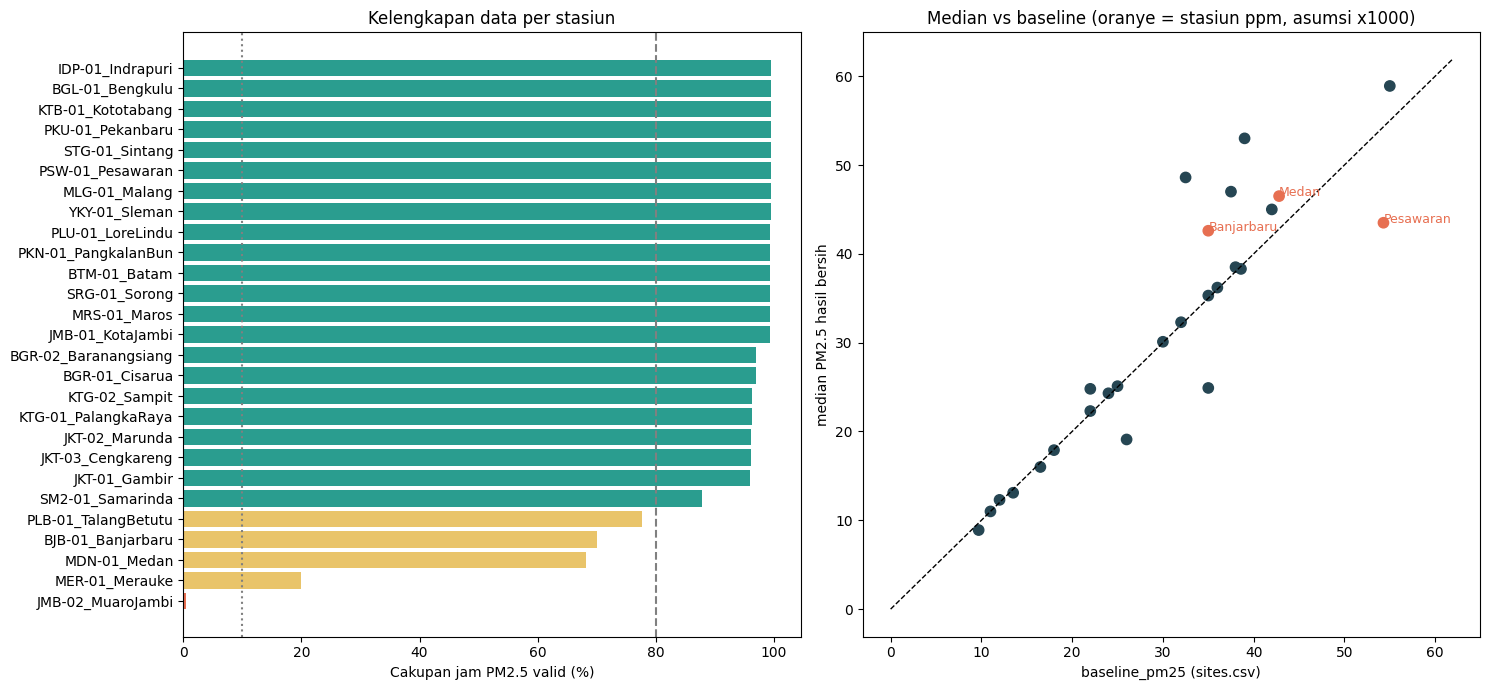

Rentang tanggal jam: 2024-01-01 00:00:00 -> 2026-10-14 23:00:00
{'OK': 22, 'CAUTION': 4, 'EXCLUDED': 1}


In [ ]:
# ---- pemeriksaan otomatis
assert hourly.pm25.dropna().between(0.1, 2000).all()
assert hourly.humidity_pct.dropna().between(0, 100).all()
assert not np.isinf(hourly.select_dtypes("number")).any().any()
assert hourly.duplicated(["location_id", "hour"]).sum() == 0
assert (hourly.pm25.dropna() <= hourly.pm10.reindex(hourly.pm25.dropna().index) * PM_RATIO_TOL + 1.0).all()
assert daily.duplicated(["location_id", "date"]).sum() == 0
assert h.duplicated(["hospital_id", "date"]).sum() == 0
for _loc, _d in hourly_all.groupby("location_id"):
    assert not frozen_hours_mask(_d.set_index("hour")).any(), f"masih ada nilai beku di {_loc}"
for _loc in SUSPECT_ACCEPT_STATIONS & set(hourly.location_id):
    assert hourly.loc[hourly.location_id == _loc, "pm25"].max() < OVERRANGE_CODE, "kode 999 masih ada di PM2.5"
print("Semua pemeriksaan otomatis lolos.\n")

# ---- gambar
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
a = audit.sort_values("coverage_pm25")
col = a.status.map({"OK": "#2a9d8f", "CAUTION": "#e9c46a", "EXCLUDED": "#e76f51"})
ax[0].barh(a.label, a.coverage_pm25 * 100, color=col)
ax[0].axvline(COVERAGE_OK * 100, ls="--", c="gray"); ax[0].axvline(COVERAGE_EXCLUDE * 100, ls=":", c="gray")
ax[0].set_xlabel("Cakupan jam PM2.5 valid (%)"); ax[0].set_title("Kelengkapan data per stasiun")

b = audit[audit.status != "EXCLUDED"]
ax[1].scatter(b.baseline_pm25, b.pm25_median, c=np.where(b.pm_from_ppm, "#e76f51", "#264653"), s=55)
for _, r in b[b.pm_from_ppm].iterrows():
    ax[1].annotate(r.label.split("_")[1], (r.baseline_pm25, r.pm25_median), fontsize=9, color="#e76f51")
lim = max(b.baseline_pm25.max(), b.pm25_median.max()) * 1.05
ax[1].plot([0, lim], [0, lim], "k--", lw=1)
ax[1].set_xlabel("baseline_pm25 (sites.csv)"); ax[1].set_ylabel("median PM2.5 hasil bersih")
ax[1].set_title("Median vs baseline (oranye = stasiun ppm, asumsi x1000)")
plt.tight_layout(); plt.show()

print("Rentang tanggal jam:", hourly.hour.min(), "->", hourly.hour.max())
print(audit.status.value_counts().to_dict())

## 12. Simpan dan unduh

In [ ]:
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir()

hourly_cols = ["station", "location_id", "island", "site_type", "hour", "date", "hour_of_day", "dow",
               "is_weekend", "month", "year"] + VARS + ["n_rows", "frozen", "pm25_overrange", "pm_from_ppm"]
hourly[hourly_cols].to_csv(OUT / "aqms_hourly_clean.csv", index=False, float_format="%.3f")
daily.to_csv(OUT / "aqms_daily_clean.csv", index=False, float_format="%.3f")
h.to_csv(OUT / "health_clean.csv", index=False)
merged.to_csv(OUT / "analysis_daily_merged.csv", index=False, float_format="%.3f")
stations.drop(columns=["sensor_id"]).to_csv(OUT / "stations_master_clean.csv", index=False)
audit.drop(columns=["pm_unit_source"]).to_csv(OUT / "station_quality_report.csv", index=False)
iku_st.to_csv(OUT / "iku_station_year.csv", index=False, float_format="%.3f")
city.to_csv(OUT / "iku_city_year.csv", index=False, float_format="%.3f")

dd = [
 ("pm25..no2", "Konsentrasi polutan, SELURUHNYA dalam ug/m3 (gas ppm sudah dikonversi)"),
 ("co", "Karbon monoksida (ug/m3)"),
 ("temperature_c / humidity_pct", "Suhu (C) dan kelembapan relatif (%)"),
 ("wind_speed_ms / wind_direction_deg", "Kecepatan angin (m/s) dan arah asal angin (derajat, rata-rata sirkular)"),
 ("hour", "Awal jam pengukuran (WIB sesuai dokumen), sudah dibulatkan ke jam"),
 ("n_rows", "Jumlah pembacaan mentah yang diterima dalam jam tsb (0 = tidak ada data lolos)"),
 ("pm_from_ppm", "True = PM berasal dari ppm dan dikonversi dengan faktor ASUMSI (jangan dipakai untuk peringkat absolut)"),
 ("island", "Pulau/kelompok pulau, dipetakan dari provinsi"),
 ("pm25 (harian)", "Rata-rata 24 jam, hanya jika >= 18 jam data valid, selain itu kosong"),
 ("pm25_max_1h", "Nilai maksimum PM2.5 per jam dalam hari tsb"),
 ("n_hours_pm25", "Jumlah jam PM2.5 valid dalam hari tsb"),
 ("resp_admissions_under5 dst.", "Kasus kesehatan harian dari HLT-01 (tanpa imputasi)"),
 ("time_idx", "Nomor hari dihitung ulang dari tanggal (kolom `time` asli tidak konsisten di sebagian RS)"),
 ("status (audit)", "OK / CAUTION / EXCLUDED berdasarkan cakupan PM2.5"),
]
dd += [
 ("resp_admissions_over60", "Jumlah rawat inap akibat gangguan pernapasan (ISPA) pada lansia > 60 tahun (info panitia)"),
 ("resp_admissions_under5", "Rawat inap gangguan pernapasan pada anak < 5 tahun (arti dari nama kolom; definisi rinci belum dikonfirmasi)"),
 ("asthma_emergency_cases / copd_admissions", "Kasus gawat darurat asma / rawat inap PPOK (arti dari nama kolom)"),
 ("resp / cvd / death", "Total kasus pernapasan / kardiovaskular / kematian (arti dari nama kolom; definisi rinci belum dikonfirmasi)"),
 ("dow / is_weekend / month / year", "Nama hari, penanda akhir pekan (Sabtu-Minggu), bulan, dan tahun dari tanggal/jam"),
 ("days_valid_pm25 / _so2 / _no2", "Jumlah hari dengan rata-rata 24 jam valid (>= MIN_HOURS_PER_DAY jam) per stasiun (audit: seluruh periode; IKU: per tahun)"),
 ("coverage_days_*", "Hari valid dibagi jumlah hari dalam periode"),
 ("iku_eligible", "True bila hari valid SO2 dan NO2 >= 80% hari tahun itu (syarat AQMS stasiun tetap)"),
 ("so2_annual / no2_annual", "Rata-rata tahunan dari rata-rata harian valid (ug/m3)"),
 ("ieu", "Indeks udara model EU = 0,5 x SO2/acuan + 0,5 x NO2/acuan"),
 ("iku_raw / iku", "IKU = 100 - (50/0,9) x (Ieu - 0,1). iku dipotong ke 0-100 (IKU_CLIP) dan hanya terisi bila layak. ESTIMASI dari AQMS, bukan IKU resmi passive sampler"),
 ("iku_sens_0C", "IKU bila acuan konsentrasi pada 0 C (ug/Nm3), uji sensitivitas"),
]
dd += [
 ("frozen", "True = jam dikosongkan karena nilai beku (sensor macet): nilai identik >= FROZEN_MIN_RUN jam di >= FROZEN_MIN_VARS polutan, walau flag VALID"),
 ("pm25_overrange", "True = jam berkode 999 (PM melewati rentang) yang dikosongkan; hanya dipetakan untuk SUSPECT_ACCEPT_STATIONS. PM2.5 jam itu kosong tetapi kemungkinan sangat tinggi"),
 ("pm25_overrange_hours / pm25_lower_bound", "Jumlah jam 999 pada hari tsb / True bila rata-rata PM2.5 harian harus dibaca sebagai BATAS BAWAH"),
 ("frozen_hours / suspect_accepted / overrange_hours (audit)", "Jumlah jam beku dikosongkan / baris SUSPECT non-999 diterima / jam kode 999 dikosongkan, per stasiun"),
 ("full_year (iku_city_year)", "True bila semua stasiun-tahun penyusun mencakup satu tahun penuh; False = tahun parsial (mis. 2026 s.d. 14 Okt), jangan dibandingkan langsung dengan tahun penuh"),
]
pd.DataFrame(dd, columns=["kolom", "keterangan"]).to_csv(OUT / "data_dictionary.csv", index=False)

shutil.make_archive("hasil_bersih", "zip", OUT)
for p in sorted(OUT.iterdir()):
    print(f"{p.name:<32} {p.stat().st_size/1e6:7.2f} MB")

if SAVE_TO_DRIVE and DRIVE_ROOT.exists():
    DRIVE_OUT.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT, DRIVE_OUT, dirs_exist_ok=True)
    shutil.copy("hasil_bersih.zip", DRIVE_OUT / "hasil_bersih.zip")
    print("\nTersimpan di Google Drive:", DRIVE_OUT)
else:
    print("\nDrive tidak aktif, hasil hanya ada di folder lokal:", OUT.resolve())

if IN_COLAB and DOWNLOAD_ZIP:
    files.download("hasil_bersih.zip")

analysis_daily_merged.csv           7.29 MB
aqms_daily_clean.csv                4.79 MB
aqms_hourly_clean.csv             127.41 MB
data_dictionary.csv                 0.00 MB
health_clean.csv                    4.22 MB
iku_city_year.csv                   0.01 MB
iku_station_year.csv                0.01 MB
station_quality_report.csv          0.01 MB
stations_master_clean.csv           0.01 MB

Tersimpan di Google Drive: /content/drive/MyDrive/hasil_bersih
